<a href="https://colab.research.google.com/github/dzakki08/Studi_Kasus_Make_Sense_of_Data_with_Analysis_and_AI_.ipynb/blob/main/Studi_Kasus_Final_Prediksi_Customer_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAPORAN STUDI KASUS MACHINE LEARNING
# Prediksi Pelanggan Berhenti Berlangganan (*Customer Churn*)

**Nama:** Muhammad Farhan Dzakki  
**NPM:** G1A023041  
**Program Studi:** Informatika  
**Fakultas:** Teknik  
**Universitas:** Universitas Bengkulu  

---

## Ringkasan

Studi kasus ini membahas penerapan *machine learning* untuk mengklasifikasikan pelanggan layanan internet yang berpotensi berhenti berlangganan (*customer churn*). Proses analisis meliputi pemahaman masalah, pembuatan dan pemeriksaan dataset simulasi, eksplorasi data, persiapan fitur, pelatihan beberapa algoritma klasifikasi, evaluasi model, serta contoh prediksi pelanggan baru.

**Catatan penting:** Dataset dalam notebook ini dibuat secara sintetis untuk tujuan pembelajaran, bukan berasal dari perusahaan atau pelanggan nyata. Karena itu, hasil model merupakan demonstrasi metode dan tidak dapat dianggap sebagai gambaran kinerja pada data operasional.

## 1. Business Understanding

### 1.1 Latar Belakang
Pelanggan yang berhenti menggunakan layanan dapat berdampak pada pendapatan dan pertumbuhan perusahaan. Perusahaan dapat memanfaatkan analisis data untuk mengenali karakteristik pelanggan yang berpotensi berhenti, kemudian meninjau pengalaman pelanggan dan menentukan tindak lanjut yang sesuai.

### 1.2 Rumusan Masalah
1. Bagaimana karakteristik pelanggan yang berhenti berlangganan dibandingkan pelanggan yang tetap berlangganan?
2. Bagaimana membangun model klasifikasi untuk memprediksi kemungkinan *churn*?
3. Algoritma mana yang menghasilkan keseimbangan metrik evaluasi terbaik pada dataset simulasi?

### 1.3 Tujuan
- Memahami karakteristik dan distribusi data pelanggan.
- Melakukan eksplorasi data menggunakan statistik deskriptif dan visualisasi.
- Membandingkan Logistic Regression, Decision Tree, dan Random Forest.
- Mengevaluasi model menggunakan Accuracy, Precision, Recall, F1-score, dan ROC-AUC.
- Menunjukkan contoh penggunaan model untuk memprediksi pelanggan baru.

### 1.4 Definisi Target
Kolom `churn` merupakan target klasifikasi:
- `0` = pelanggan tetap berlangganan.
- `1` = pelanggan berhenti berlangganan.

## 2. Import Library

Library berikut digunakan untuk manipulasi data, visualisasi, pembagian dataset, preprocessing, pelatihan model, dan evaluasi. Kode menggunakan `random_state` agar hasil pembagian data dan algoritma yang mendukungnya dapat direproduksi.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_auc_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
print("Library berhasil diimpor.")

Library berhasil diimpor.


## 3. Data Understanding

Dataset sintetis dibuat untuk merepresentasikan 1.500 pelanggan. Variabel yang digunakan meliputi lama berlangganan, biaya bulanan, jumlah keluhan, keterlambatan pembayaran, gangguan layanan, jenis paket, metode pembayaran, dan status *churn*.

| Kolom | Keterangan |
|---|---|
| `lama_berlangganan_bulan` | Lama pelanggan menggunakan layanan |
| `biaya_bulanan` | Biaya layanan per bulan |
| `jumlah_keluhan` | Jumlah keluhan yang tercatat |
| `pernah_telat_bayar` | 1 jika pernah terlambat membayar, selain itu 0 |
| `gangguan_bulan_ini` | 1 jika mengalami gangguan bulan ini, selain itu 0 |
| `jenis_paket` | Basic, Standard, atau Premium |
| `metode_pembayaran` | Metode pembayaran pelanggan |
| `churn` | Target: 1 berhenti, 0 tetap berlangganan |

Karena dataset dibangkitkan melalui aturan simulasi, hubungan yang ditemukan model sebagian berasal dari aturan pembentukan data itu sendiri.

In [4]:
# Membuat dataset sintetis (bukan data pelanggan nyata)
n = 1500

lama_berlangganan = np.random.randint(1, 73, n)
biaya_bulanan = np.random.normal(450_000, 120_000, n).clip(150_000, 900_000).round(0)
jumlah_keluhan = np.random.poisson(1.2, n).clip(0, 8)
telat_bayar = np.random.binomial(1, 0.28, n)
gangguan_bulan_ini = np.random.binomial(1, 0.22, n)
jenis_paket = np.random.choice(["Basic", "Standard", "Premium"], n, p=[0.35, 0.45, 0.20])
metode_bayar = np.random.choice(["Transfer", "Kartu", "E-Wallet", "Autodebit"], n, p=[0.30, 0.20, 0.25, 0.25])

# Probabilitas churn ditentukan oleh kombinasi variabel simulasi
logit = (
    -1.5
    - 0.035 * lama_berlangganan
    + 0.45 * jumlah_keluhan
    + 0.75 * telat_bayar
    + 0.65 * gangguan_bulan_ini
    + (jenis_paket == "Basic") * 0.35
    - (metode_bayar == "Autodebit") * 0.35
)
prob_churn = 1 / (1 + np.exp(-logit))
churn = np.random.binomial(1, prob_churn)

df = pd.DataFrame({
    "lama_berlangganan_bulan": lama_berlangganan,
    "biaya_bulanan": biaya_bulanan,
    "jumlah_keluhan": jumlah_keluhan,
    "pernah_telat_bayar": telat_bayar,
    "gangguan_bulan_ini": gangguan_bulan_ini,
    "jenis_paket": jenis_paket,
    "metode_pembayaran": metode_bayar,
    "churn": churn
})

print("Lima data pertama:")
display(df.head())
print("Ukuran dataset:", df.shape)

Lima data pertama:


,lama_berlangganan_bulan,biaya_bulanan,jumlah_keluhan,pernah_telat_bayar,gangguan_bulan_ini,jenis_paket,metode_pembayaran,churn
0,52,411558.0,2,0,0,Premium,Transfer,0
1,15,500900.0,1,0,0,Premium,E-Wallet,0
2,72,512740.0,1,1,0,Standard,E-Wallet,0
3,61,381156.0,5,1,1,Standard,Transfer,0
4,21,447077.0,1,0,1,Standard,Kartu,0


Ukuran dataset: (1500, 8)


In [5]:
print("Informasi dataset:")
df.info()

print("\\nStatistik deskriptif:")
display(df.describe(include="all").T)

print("\\nJumlah missing value per kolom:")
display(df.isna().sum().to_frame("jumlah_missing"))

print("Jumlah baris duplikat:", df.duplicated().sum())
print("\\nDistribusi target:")
display(df["churn"].value_counts().sort_index().rename(index={0: "Tetap berlangganan (0)", 1: "Berhenti (1)"}).to_frame("jumlah"))

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   lama_berlangganan_bulan  1500 non-null   int64  
 1   biaya_bulanan            1500 non-null   float64
 2   jumlah_keluhan           1500 non-null   int64  
 3   pernah_telat_bayar       1500 non-null   int64  
 4   gangguan_bulan_ini       1500 non-null   int64  
 5   jenis_paket              1500 non-null   object 
 6   metode_pembayaran        1500 non-null   object 
 7   churn                    1500 non-null   int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 93.9+ KB
\nStatistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
lama_berlangganan_bulan,1500.0,NaN,NaN,NaN,35.870667,20.857228,1.0,17.0,36.0,54.0,72.0
biaya_bulanan,1500.0,NaN,NaN,NaN,454731.654667,117877.220137,150000.0,375094.0,452626.5,532459.75,833173.0
jumlah_keluhan,1500.0,NaN,NaN,NaN,1.18,1.062867,0.0,0.0,1.0,2.0,5.0
pernah_telat_bayar,1500.0,NaN,NaN,NaN,0.258667,0.438048,0.0,0.0,0.0,1.0,1.0
gangguan_bulan_ini,1500.0,NaN,NaN,NaN,0.205333,0.40408,0.0,0.0,0.0,0.0,1.0
jenis_paket,1500,3,Standard,686,NaN,NaN,NaN,NaN,NaN,NaN,NaN
metode_pembayaran,1500,4,Transfer,443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
churn,1500.0,NaN,NaN,NaN,0.175333,0.380379,0.0,0.0,0.0,0.0,1.0


\nJumlah missing value per kolom:


,jumlah_missing
lama_berlangganan_bulan,0
biaya_bulanan,0
jumlah_keluhan,0
pernah_telat_bayar,0
gangguan_bulan_ini,0
jenis_paket,0
metode_pembayaran,0
churn,0


Jumlah baris duplikat: 0
\nDistribusi target:


,jumlah
churn,
Tetap berlangganan (0),1237
Berhenti (1),263


## 4. Exploratory Data Analysis (EDA)

EDA digunakan untuk memahami distribusi target dan melihat pola awal pada beberapa fitur. Visualisasi membantu membentuk pertanyaan analisis, tetapi tidak membuktikan bahwa suatu variabel menyebabkan pelanggan berhenti.

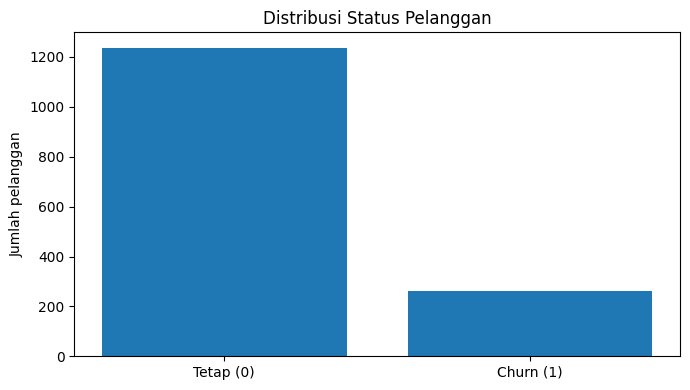

Persentase churn pada dataset simulasi: 17.53%


In [6]:
# Distribusi status pelanggan
counts = df["churn"].value_counts().sort_index()
plt.figure(figsize=(7, 4))
plt.bar(["Tetap (0)", "Churn (1)"], counts.values)
plt.title("Distribusi Status Pelanggan")
plt.ylabel("Jumlah pelanggan")
plt.tight_layout()
plt.show()

print(f"Persentase churn pada dataset simulasi: {df['churn'].mean() * 100:.2f}%")

<Figure size 700x400 with 0 Axes>

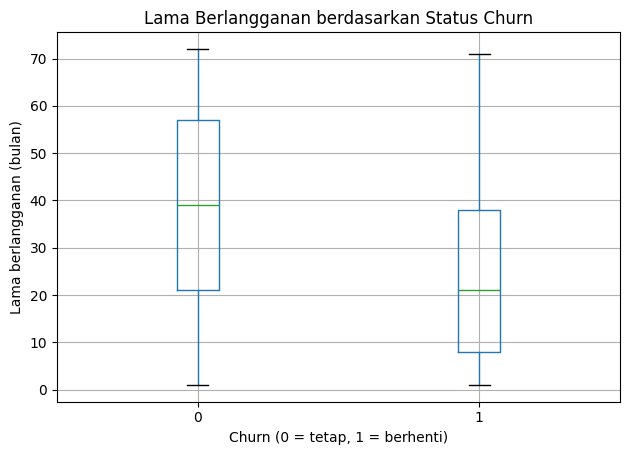

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,1237.0,38.24,20.58,1.0,21.0,39.0,57.0,72.0
1,263.0,24.73,18.43,1.0,8.0,21.0,38.0,71.0


In [7]:
# Lama berlangganan berdasarkan status churn
plt.figure(figsize=(7, 4))
df.boxplot(column="lama_berlangganan_bulan", by="churn")
plt.title("Lama Berlangganan berdasarkan Status Churn")
plt.suptitle("")
plt.xlabel("Churn (0 = tetap, 1 = berhenti)")
plt.ylabel("Lama berlangganan (bulan)")
plt.tight_layout()
plt.show()

display(df.groupby("churn")["lama_berlangganan_bulan"].describe().round(2))

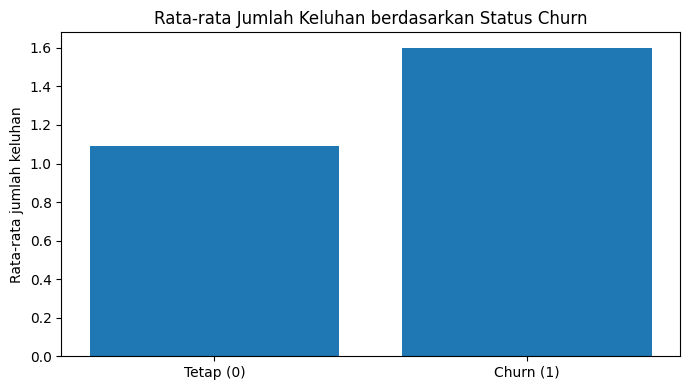

,rata_rata_keluhan
churn,
Tetap berlangganan,1.09
Berhenti,1.60


In [8]:
# Rata-rata jumlah keluhan menurut status churn
rata_keluhan = df.groupby("churn")["jumlah_keluhan"].mean()
plt.figure(figsize=(7, 4))
plt.bar(["Tetap (0)", "Churn (1)"], rata_keluhan.values)
plt.title("Rata-rata Jumlah Keluhan berdasarkan Status Churn")
plt.ylabel("Rata-rata jumlah keluhan")
plt.tight_layout()
plt.show()

display(rata_keluhan.rename(index={0: "Tetap berlangganan", 1: "Berhenti"}).to_frame("rata_rata_keluhan").round(2))

### Interpretasi EDA

Perhatikan grafik distribusi target, lama berlangganan, dan jumlah keluhan. Bandingkan nilai atau pola antara pelanggan yang tetap dan yang berhenti. Pada data simulasi ini, status *churn* dibentuk dengan mempertimbangkan beberapa fitur, sehingga perbedaan yang tampak tidak boleh langsung digeneralisasi ke pelanggan nyata.

## 5. Data Preparation

Kolom target `churn` dipisahkan dari fitur agar tidak terjadi kebocoran target. Data dibagi menjadi 80% data latih dan 20% data uji menggunakan `stratify=y` agar proporsi kelas tetap relatif terjaga. Preprocessing dilakukan di dalam pipeline dan dipelajari hanya dari data latih.

- **Fitur numerik:** nilai kosong diisi dengan median dan fitur distandardisasi.
- **Fitur kategorikal:** nilai kosong diisi dengan modus dan kategori diubah dengan One-Hot Encoding.
- `handle_unknown="ignore"` menangani kategori yang mungkin tidak ditemukan ketika pelatihan.

In [9]:
target = "churn"
X = df.drop(columns=[target])
y = df[target]

numeric_features = [
    "lama_berlangganan_bulan", "biaya_bulanan", "jumlah_keluhan",
    "pernah_telat_bayar", "gangguan_bulan_ini"
]
categorical_features = ["jenis_paket", "metode_pembayaran"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Jumlah data:", len(df))
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi churn pada data latih:", round(y_train.mean() * 100, 2), "%")
print("Proporsi churn pada data uji:", round(y_test.mean() * 100, 2), "%")

Jumlah data: 1500
Data latih: (1200, 7) | Data uji: (300, 7)
Proporsi churn pada data latih: 17.5 %
Proporsi churn pada data uji: 17.67 %


## 6. Modeling

Tiga algoritma klasifikasi dibandingkan:

1. **Logistic Regression** — model dasar yang mempelajari hubungan linear antara fitur dan peluang kelas.
2. **Decision Tree** — model berbasis aturan percabangan yang dapat menangkap pola nonlinier.
3. **Random Forest** — gabungan banyak pohon keputusan untuk menghasilkan prediksi yang lebih stabil dibanding satu pohon pada banyak kasus.

`class_weight="balanced"` digunakan untuk memberi bobot pada kelas sesuai frekuensinya. Pemilihan model dalam studi kasus ini didasarkan pada F1-score data uji, namun metrik lain tetap perlu diperhatikan sesuai kebutuhan bisnis.

In [10]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, class_weight="balanced", random_state=RANDOM_STATE
    )
}

fitted_models = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    fitted_models[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
print("Perbandingan kinerja model (diurutkan berdasarkan F1-score):")
display(results_df.round(3))

Perbandingan kinerja model (diurutkan berdasarkan F1-score):


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.82,0.491,0.509,0.500,0.790
1,Logistic Regression,0.70,0.342,0.755,0.471,0.816
2,Decision Tree,0.64,0.290,0.717,0.413,0.718


## 7. Evaluation

Metrik evaluasi memiliki makna yang berbeda:

- **Accuracy:** proporsi seluruh prediksi yang benar.
- **Precision:** proporsi prediksi churn yang memang benar-benar churn.
- **Recall:** proporsi pelanggan churn aktual yang berhasil dikenali.
- **F1-score:** rata-rata harmonis Precision dan Recall.
- **ROC-AUC:** kemampuan model membedakan kelas pada berbagai ambang probabilitas.

Dalam konteks retensi, Recall dapat menjadi penting karena perusahaan mungkin ingin mengidentifikasi sebanyak mungkin pelanggan yang berisiko. Namun, Precision juga penting agar tindak lanjut tidak terlalu banyak diarahkan kepada pelanggan yang sebenarnya tidak akan berhenti.

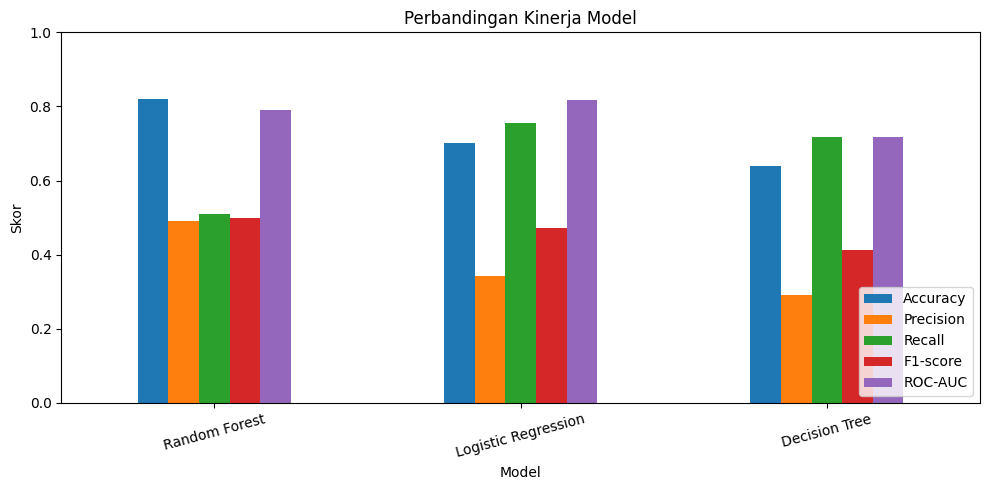

In [11]:
# Perbandingan metrik seluruh model
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
plot_df = results_df.set_index("Model")[metrics]
plot_df.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
plt.title("Perbandingan Kinerja Model")
plt.ylabel("Skor")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Model terpilih berdasarkan F1-score: Random Forest
\nClassification report:
                    precision    recall  f1-score   support

Tetap berlangganan       0.89      0.89      0.89       247
             Churn       0.49      0.51      0.50        53

          accuracy                           0.82       300
         macro avg       0.69      0.70      0.70       300
      weighted avg       0.82      0.82      0.82       300

Confusion matrix (baris = kelas aktual, kolom = prediksi):


,Prediksi tetap,Prediksi churn
Aktual tetap,219,28
Aktual churn,26,27


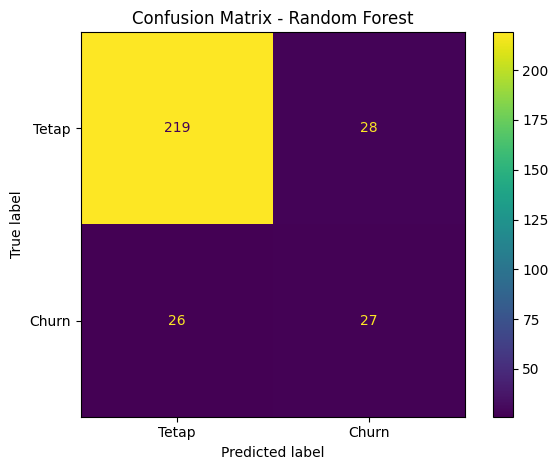

In [12]:
# Evaluasi model dengan F1-score tertinggi
best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test)

print("Model terpilih berdasarkan F1-score:", best_name)
print("\\nClassification report:")
print(classification_report(
    y_test, best_pred, target_names=["Tetap berlangganan", "Churn"], zero_division=0
))

cm = confusion_matrix(y_test, best_pred)
print("Confusion matrix (baris = kelas aktual, kolom = prediksi):")
display(pd.DataFrame(
    cm,
    index=["Aktual tetap", "Aktual churn"],
    columns=["Prediksi tetap", "Prediksi churn"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    display_labels=["Tetap", "Churn"],
    values_format="d"
)
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

### Interpretasi Evaluasi

Gunakan tabel perbandingan metrik dan confusion matrix yang dihasilkan saat notebook dijalankan untuk menilai model. Model dengan F1-score tertinggi dipilih sebagai model contoh, bukan berarti otomatis menjadi model terbaik untuk semua kebutuhan. Kesalahan *false positive* dan *false negative* memiliki konsekuensi bisnis yang berbeda, sehingga keputusan akhir sebaiknya mempertimbangkan tujuan tim retensi.

## 8. Prediksi Pelanggan Baru

Bagian ini menunjukkan cara menggunakan model terpilih pada satu pelanggan hipotetis. Nilai probabilitas merupakan estimasi model berdasarkan pola data simulasi dan bukan kepastian mengenai perilaku pelanggan.

In [13]:
pelanggan_baru = pd.DataFrame([{
    "lama_berlangganan_bulan": 5,
    "biaya_bulanan": 620000,
    "jumlah_keluhan": 3,
    "pernah_telat_bayar": 1,
    "gangguan_bulan_ini": 1,
    "jenis_paket": "Basic",
    "metode_pembayaran": "Transfer"
}])

prediksi = best_model.predict(pelanggan_baru)[0]
probabilitas = best_model.predict_proba(pelanggan_baru)[0, 1]

print("Data pelanggan yang diprediksi:")
display(pelanggan_baru)
print("Hasil klasifikasi:", "Berpotensi berhenti" if prediksi == 1 else "Cenderung tetap berlangganan")
print(f"Probabilitas churn menurut model: {probabilitas:.1%}")

Data pelanggan yang diprediksi:


,lama_berlangganan_bulan,biaya_bulanan,jumlah_keluhan,pernah_telat_bayar,gangguan_bulan_ini,jenis_paket,metode_pembayaran
0,5,620000,3,1,1,Basic,Transfer


Hasil klasifikasi: Cenderung tetap berlangganan
Probabilitas churn menurut model: 37.9%


## 9. Rekomendasi

Berdasarkan hasil analisis pada data simulasi, rekomendasi berikut dapat dipertimbangkan sebagai contoh penerapan:

1. Tinjau keluhan dan gangguan layanan pelanggan, lalu prioritaskan penyelesaian masalah yang dapat diverifikasi.
2. Evaluasi pengalaman pelanggan baru, terutama pada periode awal berlangganan.
3. Gunakan hasil prediksi sebagai sinyal untuk pemeriksaan lebih lanjut, bukan sebagai keputusan otomatis.
4. Pada data nyata, pantau metrik model dari waktu ke waktu dan evaluasi apakah tindakan retensi benar-benar membantu pelanggan.

## 10. Kesimpulan

Studi kasus ini menerapkan alur klasifikasi *machine learning* untuk memprediksi *customer churn* menggunakan dataset sintetis. Tahapan yang dilakukan meliputi pemahaman masalah, pembuatan dataset, pemeriksaan kualitas data, EDA, preprocessing, pembagian data, pelatihan tiga algoritma, evaluasi, dan prediksi data baru.

Kinerja model dibandingkan melalui Accuracy, Precision, Recall, F1-score, dan ROC-AUC. Model contoh dipilih berdasarkan F1-score pada data uji. Angka evaluasi yang ditampilkan pada notebook merupakan hasil eksperimen terhadap data simulasi, sehingga belum dapat dijadikan bukti bahwa model akan bekerja sama baiknya pada data pelanggan nyata.

## 11. Keterbatasan dan Etika

- Dataset sintetis tidak mencerminkan kompleksitas data perusahaan yang sesungguhnya.
- Pola yang dipelajari sebagian dibentuk oleh aturan simulasi.
- Prediksi salah dapat membuat pelanggan yang tidak berisiko ikut dihubungi atau pelanggan berisiko tidak teridentifikasi.
- Jika memakai data nyata, pastikan pengumpulan dan penggunaan data memiliki dasar yang sah, akses dibatasi, serta data pribadi diminimalkan.
- Keputusan terhadap pelanggan tidak boleh hanya didasarkan pada keluaran model.

## 12. Pertanyaan Diskusi

1. Mengapa Recall dapat menjadi metrik penting dalam upaya mengurangi *churn*?
2. Apa konsekuensi bisnis jika model memiliki Precision tinggi tetapi Recall rendah?
3. Apa yang terjadi pada hasil evaluasi jika ukuran data uji diubah menjadi 30%?
4. Fitur apa yang perlu dikumpulkan secara sah jika perusahaan ingin menguji model pada data nyata?
5. Mengapa hasil dari dataset sintetis tidak boleh langsung digeneralisasi ke kondisi operasional?

---

**Akhir laporan.**